In [1]:
import seaborn as sns

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

print("Shape:", df.shape)
print(df.head())

Shape: (6433, 14)
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper Wes

In [2]:
import pandas as pd
print("Missing values before handling:\n")
print(df.isnull().sum())

Missing values before handling:

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [3]:
df = df.dropna(subset=["pickup", "fare", "distance"]).copy()

num_cols = ["passengers", "fare", "tip", "tolls", "total", "distance"]
for col in num_cols:
  if col in df.columns and df[col].isnull().sum() > 0:
    df[col] = df[col].fillna(df[col].median())

cat_cols = [
    "payment",
    "pickup_borough",
    "dropoff_borough",
    "pickup_zone",
    "dropoff_zone",
    "color",
]
for col in cat_cols:
  if col in df.columns and df[col].isnull().sum() > 0:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after handling:\n")
print(df.isnull().sum())


Missing values after handling:

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


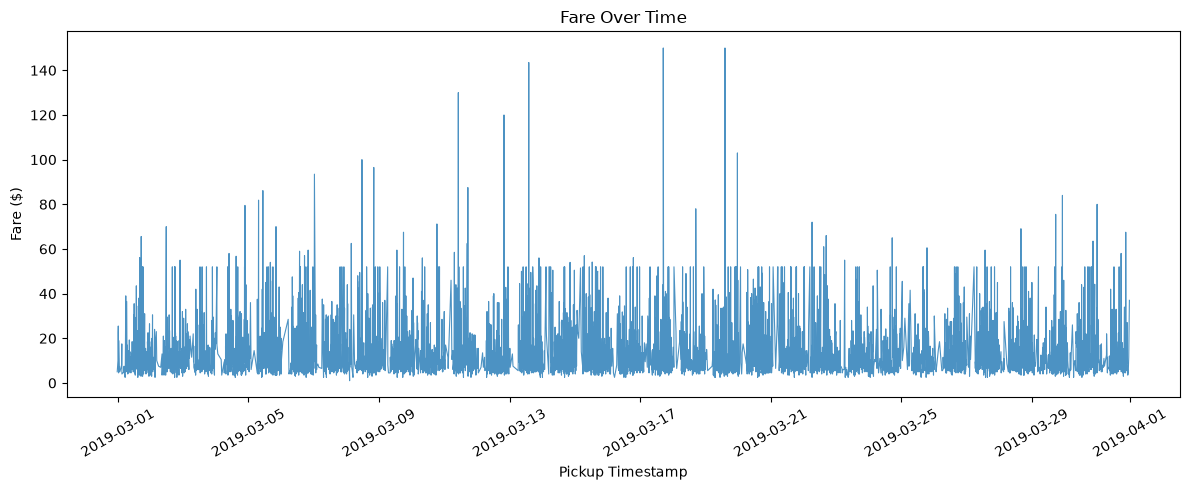

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

df["pickup"] = pd.to_datetime(df["pickup"])
df_sorted = df.sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(df_sorted["pickup"], df_sorted["fare"], linewidth=0.8, alpha=0.8)
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

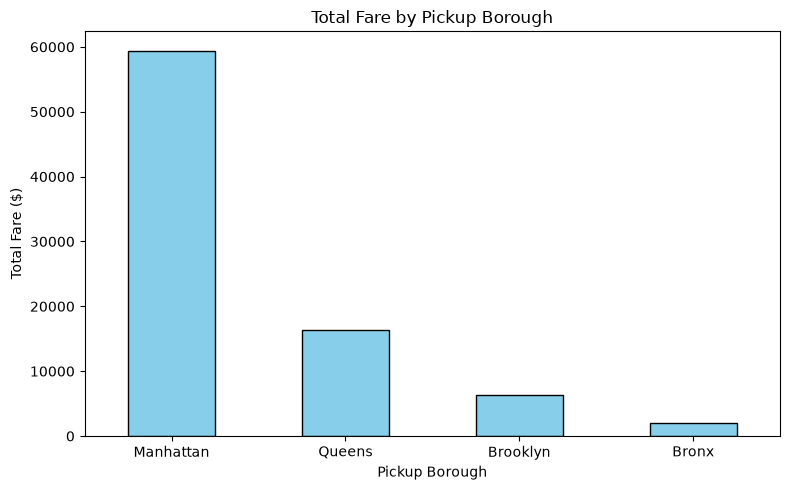

In [5]:
import matplotlib.pyplot as plt

borough_fare = df.groupby("pickup_borough")["fare"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
borough_fare.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

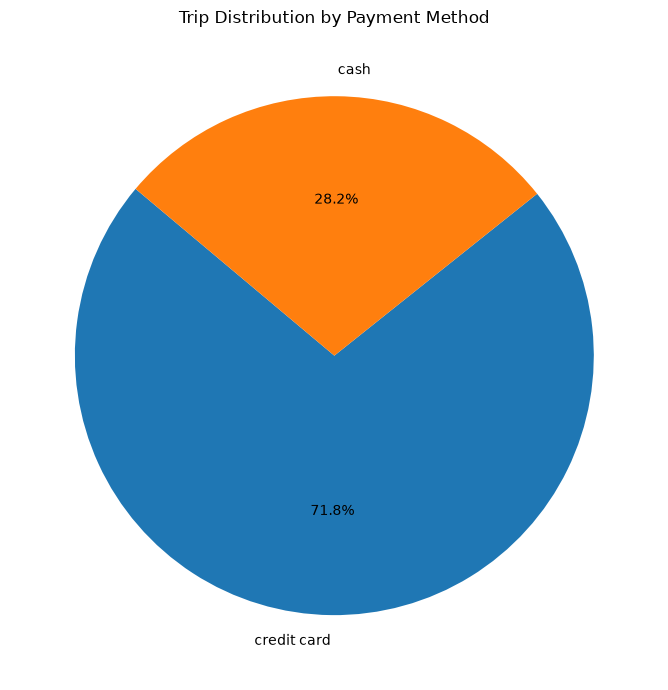

In [6]:
import matplotlib.pyplot as plt

payment_counts = df["payment"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=140,
)
plt.title("Trip Distribution by Payment Method")
plt.ylabel("")
plt.tight_layout()
plt.show()

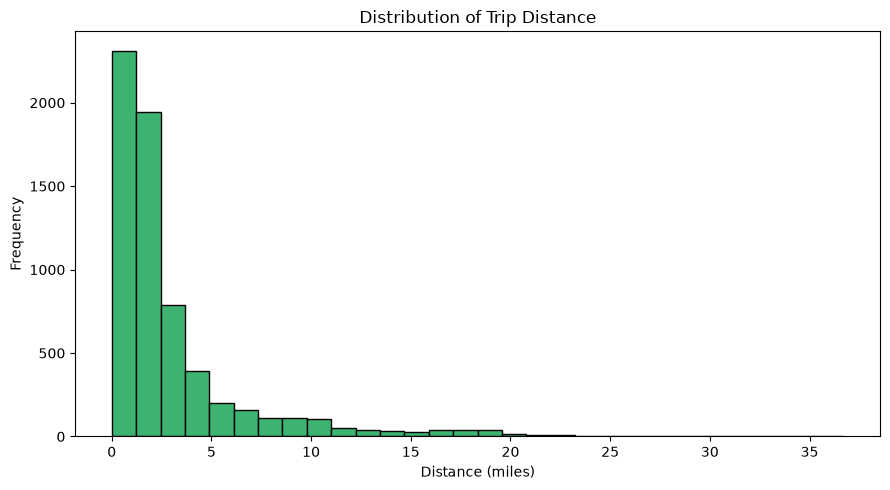

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(df["distance"], bins=30, color="mediumseagreen", edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

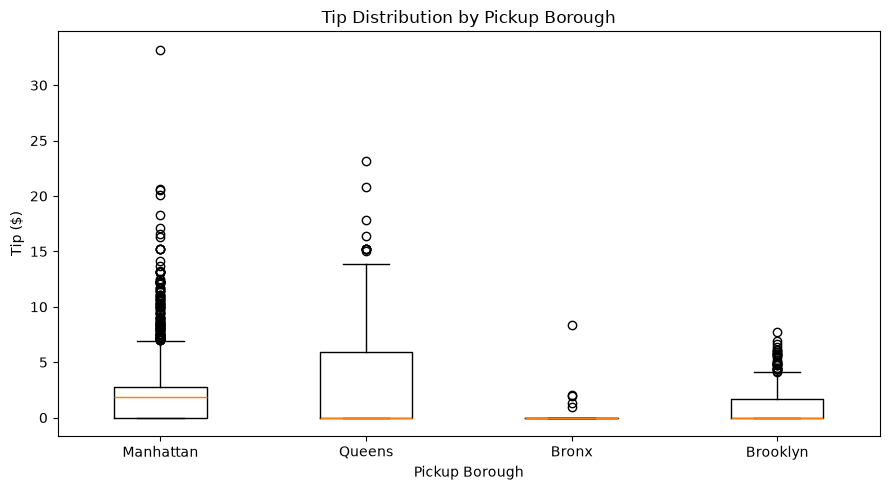

In [9]:
import matplotlib.pyplot as plt

boroughs = df["pickup_borough"].dropna().unique()
tip_data = [df[df["pickup_borough"] == b]["tip"] for b in boroughs]

plt.figure(figsize=(9, 5))
plt.boxplot(tip_data, tick_labels=boroughs)
plt.title("Tip Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.tight_layout()
plt.show()

[Text(0.5, 1.0, 'Number of Trips by Pickup Borough'),
 Text(0.5, 0, 'Pickup Borough'),
 Text(0, 0.5, 'Trip Count')]

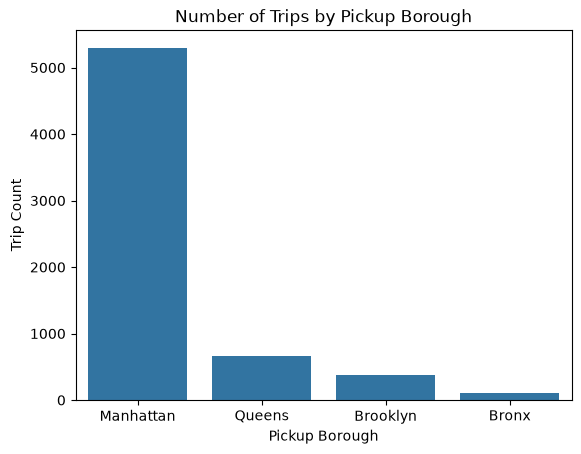

In [10]:
import seaborn as sns

ax = sns.countplot(
    data=df, x="pickup_borough", order=df["pickup_borough"].value_counts().index
)
ax.set(
    title="Number of Trips by Pickup Borough",
    xlabel="Pickup Borough",
    ylabel="Trip Count",
)

[Text(0.5, 1.0, 'Fare vs. Distance by Pickup Borough'),
 Text(0.5, 0, 'Distance (miles)'),
 Text(0, 0.5, 'Fare ($)')]

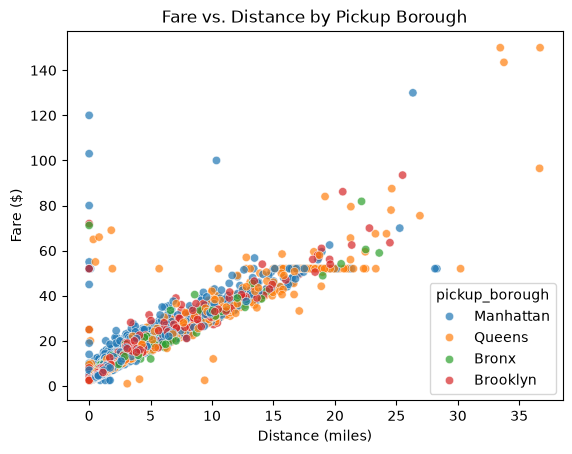

In [11]:
import seaborn as sns

ax = sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough", alpha=0.7)
ax.set(
    title="Fare vs. Distance by Pickup Borough",
    xlabel="Distance (miles)",
    ylabel="Fare ($)",
)

[Text(0.5, 1.0, 'Correlation Heatmap of Numerical Trip Variables')]

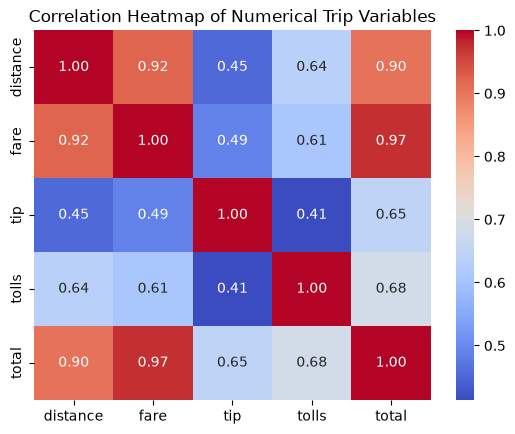

In [12]:
import seaborn as sns

corr_cols = ["distance", "fare", "tip", "tolls", "total"]
corr_matrix = df[corr_cols].corr()

ax = sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
ax.set(title="Correlation Heatmap of Numerical Trip Variables")

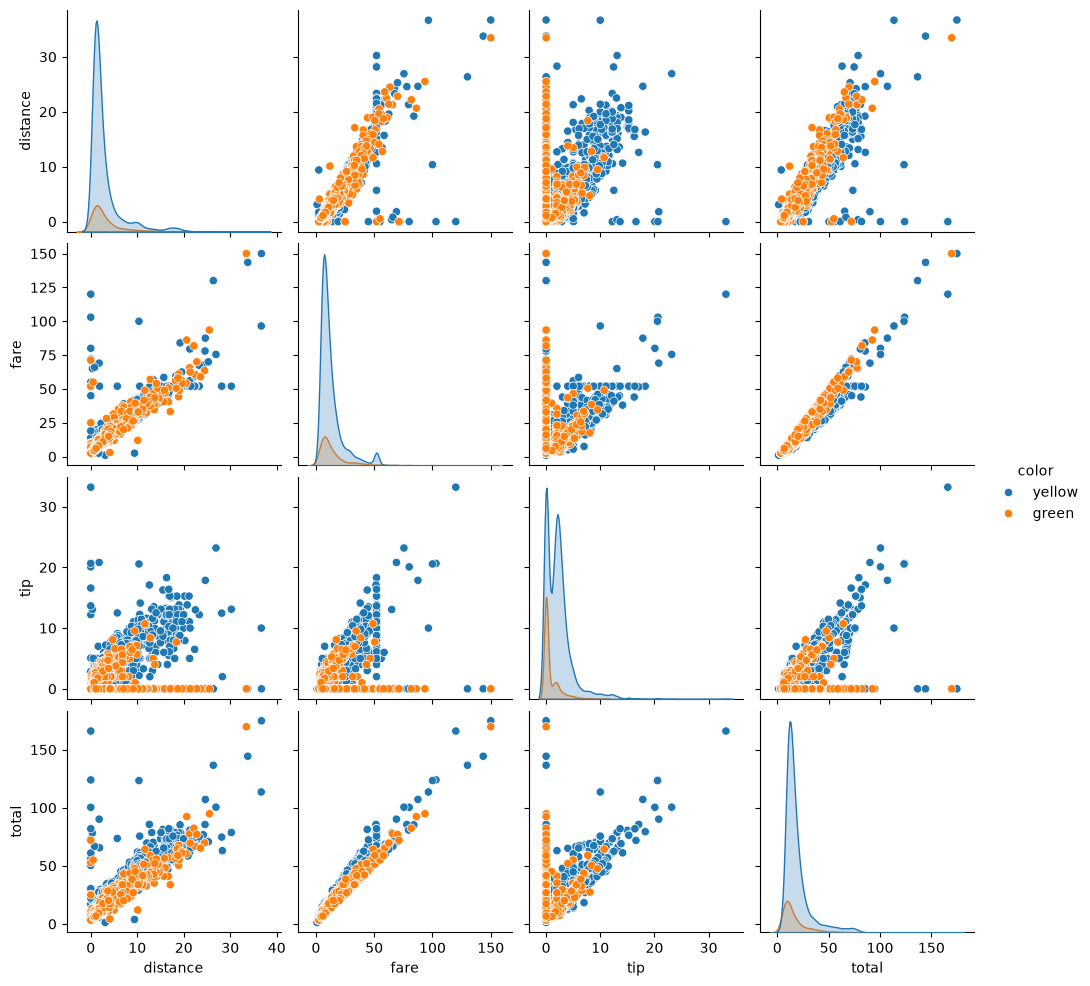

In [13]:
import seaborn as sns

pair_cols = ["distance", "fare", "tip", "total", "color"]
sns.pairplot(df[pair_cols], hue="color")

[Text(0.5, 1.0, 'Fare Distribution by Pickup Borough'),
 Text(0.5, 0, 'Pickup Borough'),
 Text(0, 0.5, 'Fare ($)')]

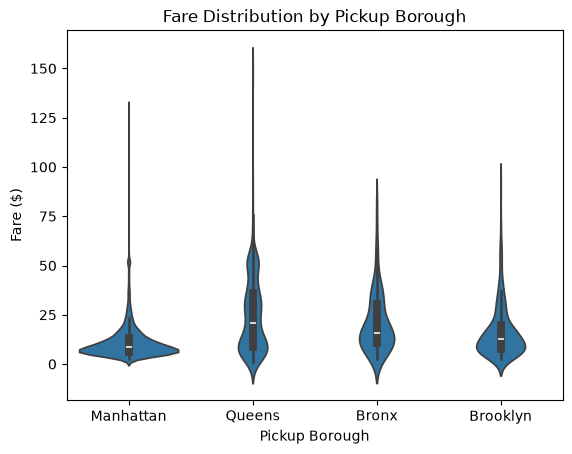

In [14]:
import seaborn as sns

ax = sns.violinplot(data=df, x="pickup_borough", y="fare")
ax.set(
    title="Fare Distribution by Pickup Borough",
    xlabel="Pickup Borough",
    ylabel="Fare ($)",
)